In [17]:
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import pickle
from hypergraphx import Hypergraph



def hyperedge_homogeneity_list(H):
    edges = [list(e) for e in H.get_edges()]

    # pair_degree[(u, v)] = how many hyperedges contain that pair
    pair_degree = {}
    for edge in edges:
        for u, v in combinations(sorted(edge), 2):
            pair_degree[(u, v)] = pair_degree.get((u, v), 0) + 1

    homogeneity = []
    for edge in edges:
        if len(edge) <= 1:
            homogeneity.append(0.0)
            continue

        pair_values = []
        for u, v in combinations(sorted(edge), 2):
            pair_values.append(pair_degree[(u, v)])

        homogeneity.append(sum(pair_values) / len(pair_values))

    return homogeneity

In [23]:
def subhypergraph(H, nodes: list):
    """Fast induced subhypergraph on `nodes` (no weights/metadata)."""
    nodes = list(nodes)
    nodes_set = set(nodes)

    candidate_edge_ids = set()
    for node in nodes:
        candidate_edge_ids.update(H._adj.get(node, []))

    edges = []
    for edge_id in candidate_edge_ids:
        edge = H._reverse_edge_list[edge_id]
        if nodes_set.issuperset(edge):
            edges.append(list(edge))

    h = Hypergraph(edges)
    h.add_nodes(nodes)  # keep isolated nodes if any
    return h

In [29]:
# All HyperLap datasets: hyperedge homogeneity + basic hypergraph stats
DATASET_DIR = Path("../www21-hyperlap-master/dataset").resolve()

homogeneity_by_dataset: dict = {}

for txt_path in sorted(DATASET_DIR.glob("*_graph.txt")):
    key = txt_path.stem.replace("_graph", "")
    print(key, flush=True)
    
    if "coauth" in key:
        print("     skipped\n")
        continue
    
    edge_list = []
    with open(txt_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens = line.replace(",", " ").split()
            edge_list.append([int(x) for x in tokens])
    print("     read the file")
    
    H = Hypergraph(edge_list)
    print("     made the hypergraph")
    if H.is_connected():
        print("     connected")
    else:
        H = H.subhypergraph_largest_component()
        print("     extracted the component")
    hom_list = hyperedge_homogeneity_list(H)
    edge_sizes = [len(e) for e in H.get_edges()]

    print("\n")
    
    homogeneity_by_dataset[key] = {
        "H": H,
        "path": str(txt_path),
        "n_nodes": len(H.get_nodes()),
        "n_edges": len(H.get_edges()),
        "hyperedge_homogeneity": hom_list,
        "mean_homogeneity": np.mean(hom_list),
        "median_homogeneity": np.median(hom_list),
        "std_homogeneity": np.std(hom_list),
        "min_edge_size": min(edge_sizes),
        "max_edge_size": max(edge_sizes),
        "mean_edge_size": np.mean(edge_sizes),
    }


NDC-classes-full
     read the file
     made the hypergraph
     extracted the component


NDC-substances-full
     read the file
     made the hypergraph
     extracted the component


coauth-DBLP-full
     skipped

coauth-geology-full
     skipped

coauth-history-full
     skipped

contact-high
     read the file
     made the hypergraph
     connected
     extracted the component


contact-primary
     read the file
     made the hypergraph
     connected
     extracted the component


email-Enron-full
     read the file
     made the hypergraph
     connected
     extracted the component


email-Eu-full
     read the file
     made the hypergraph
     connected
     extracted the component


tags-math
     read the file
     made the hypergraph
     connected
     extracted the component


tags-ubuntu
     read the file
     made the hypergraph
     connected
     extracted the component


threads-math
     read the file
     made the hypergraph


KeyboardInterrupt: 

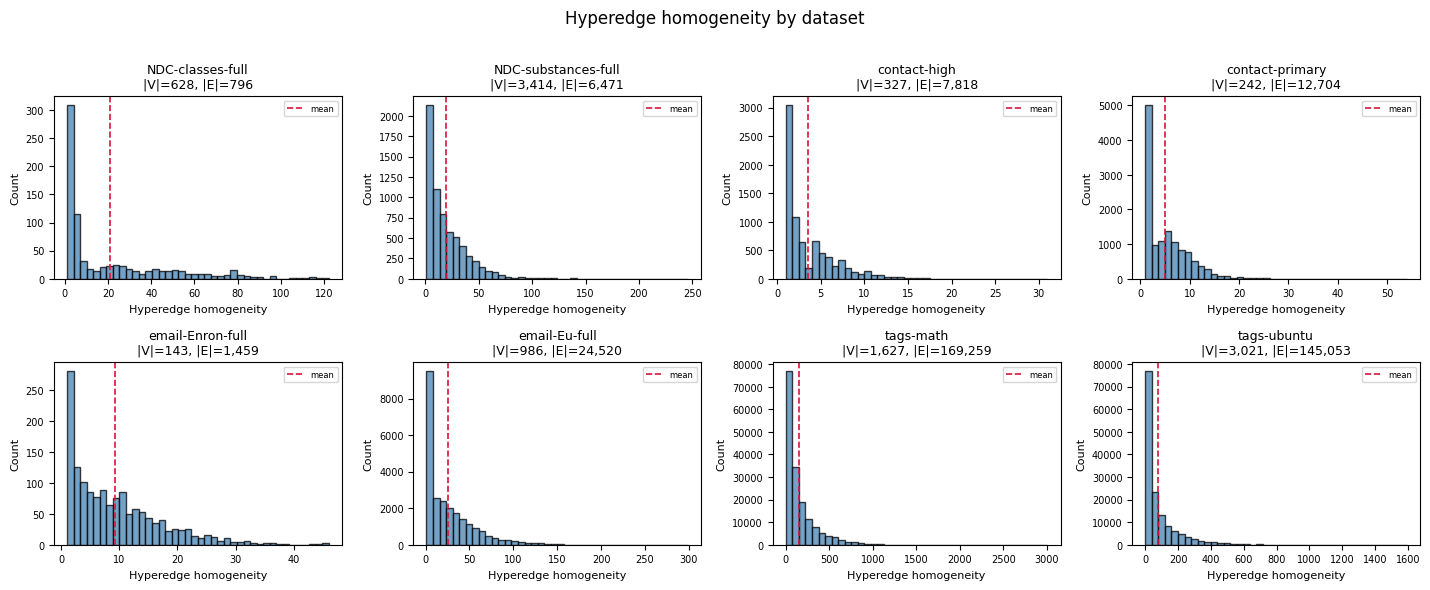

In [27]:
# Facet plot: one histogram per dataset
names = sorted(homogeneity_by_dataset.keys())
n = len(names)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.9 * nrows), squeeze=False)
axes_flat = axes.ravel()

for i, name in enumerate(names):
    ax = axes_flat[i]
    hom = homogeneity_by_dataset[name]["hyperedge_homogeneity"]
    ax.hist(hom, bins=40, edgecolor="black", alpha=0.75, color="steelblue")
    mu = float(homogeneity_by_dataset[name]["mean_homogeneity"])
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, label="mean")
    ax.legend(fontsize=6, loc="best")
    ax.set_title(
        f"{name}\n|V|={homogeneity_by_dataset[name]['n_nodes']:,}, |E|={homogeneity_by_dataset[name]['n_edges']:,}",
        fontsize=9,
    )
    ax.set_xlabel("Hyperedge homogeneity", fontsize=8)
    ax.set_ylabel("Count", fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle("Hyperedge homogeneity by dataset", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


contact-primary: mean_homogeneity: 5.03, n_edges=12704, n_nodes=242
contact-high: mean_homogeneity: 3.48, n_edges=7818, n_nodes=327
email-Enron-full: mean_homogeneity: 9.23, n_edges=1459, n_nodes=143
email-Eu-full: mean_homogeneity: 25.81, n_edges=24520, n_nodes=986
NDC-classes-full: mean_homogeneity: 20.84, n_edges=796, n_nodes=628


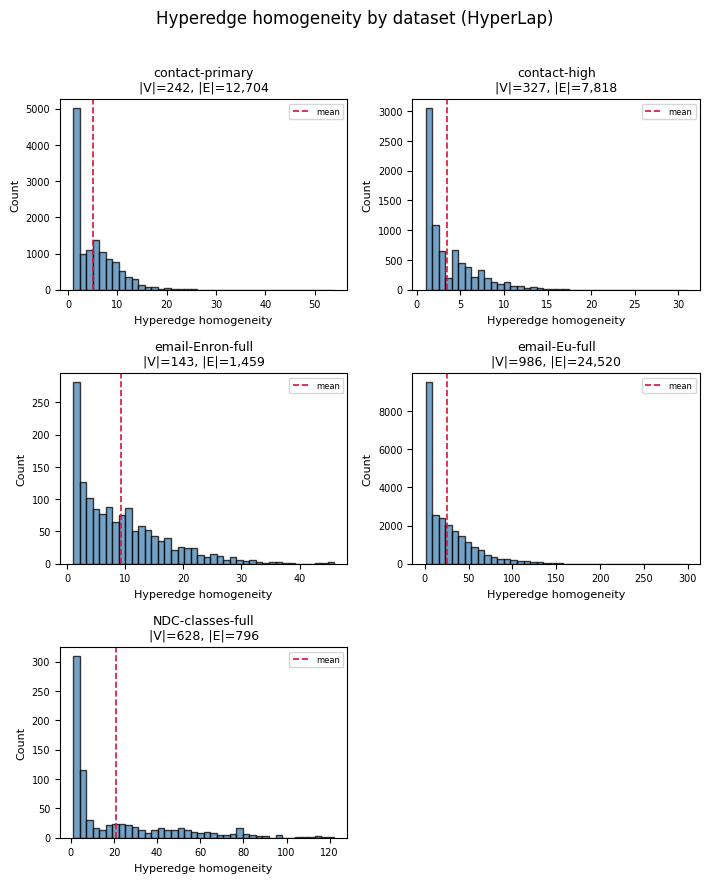

In [9]:
# Facet plot: one histogram per dataset
names = ["contact-primary", "contact-high", "email-Enron-full", "email-Eu-full", "NDC-classes-full"]
n = len(names)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.9 * nrows), squeeze=False)
axes_flat = axes.ravel()

for i, name in enumerate(names):
    ax = axes_flat[i]
    hom = homogeneity_by_dataset[name]["hyperedge_homogeneity"]
    ax.hist(hom, bins=40, edgecolor="black", alpha=0.75, color="steelblue")
    mu = float(homogeneity_by_dataset[name]["mean_homogeneity"])
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, label="mean")
    ax.legend(fontsize=6, loc="best")
    ax.set_title(
        f"{name}\n|V|={homogeneity_by_dataset[name]['n_nodes']:,}, |E|={homogeneity_by_dataset[name]['n_edges']:,}",
        fontsize=9,
    )
    ax.set_xlabel("Hyperedge homogeneity", fontsize=8)
    ax.set_ylabel("Count", fontsize=8)
    ax.tick_params(labelsize=7)
    print(f"{name}: mean_homogeneity: {round(homogeneity_by_dataset[name]['mean_homogeneity'], 2)}, n_edges={homogeneity_by_dataset[name]['n_edges']}, n_nodes={homogeneity_by_dataset[name]['n_nodes']}")

for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle("Hyperedge homogeneity by dataset (HyperLap)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


In [14]:
import pandas as pd

names = ["contact_primary", "contact_high", "email-Enron-full", "email-Eu-full"]
cp = pd.read_csv("results/contact_primary/hedge_prediction_10perc_20splits_10nw_100wl_wide.csv")
ch = pd.read_csv("results/contact-high/hedge_prediction_10perc_20splits_10nw_50wl_wide.csv")
en = pd.read_csv("results/email-Enron-full/hedge_prediction_10perc_20splits_10nw_30wl_wide.csv")
eu = pd.read_csv("results/email-Eu-full/hedge_prediction_10perc_20splits_10nw_50wl_wide.csv")
nc = pd.read_csv("results/NDC-classes-full/hedge_prediction_10perc_20splits_10nw_100wl_wide.csv")
# nc = 


In [16]:
id_cols = ['method', 'config_id', 'p', 'q', 'r', 'gamma', 'delta', 'num_walks', 'walk_length', 'dim']
names = ["contact-primary", "contact-high", "email-Enron-full", "email-Eu-full", "NDC-classes-full"]

for name, dataset in zip(names, [cp, ch, en, eu, nc]):
    dataset = dataset[(dataset["p"] > 0.5) & (dataset["q"] > 0.5)]
    dataset_filtered = dataset[dataset["delta"] != -1.0]
    dataset_grouped = dataset_filtered.groupby("method", as_index=False).agg(
        auc=("auc", "max"),
        ap=("ap", "max"),
    )
    dataset_grouped = dataset_grouped.sort_values("method")
    print(name)
    print(f"hmrw - hyper2vec = {round(dataset_grouped['auc'][0] - dataset_grouped['auc'][1], 3)}")
    print(f"homogeneity: {round(homogeneity_by_dataset[name]['mean_homogeneity'], 3)}")
    print(dataset_grouped.sort_values("auc", ascending=False))
    print("\n")

contact-primary
hmrw - hyper2vec = 0.006
homogeneity: 5.025
      method       auc        ap
0       hmrw  0.866329  0.892331
1  hyper2vec  0.859970  0.890247


contact-high
hmrw - hyper2vec = 0.004
homogeneity: 3.482
      method       auc        ap
0       hmrw  0.934171  0.945659
1  hyper2vec  0.930612  0.941924


email-Enron-full
hmrw - hyper2vec = -0.005
homogeneity: 9.233
      method       auc        ap
1  hyper2vec  0.931403  0.929605
0       hmrw  0.926580  0.921095


email-Eu-full
hmrw - hyper2vec = 0.049
homogeneity: 25.806
      method       auc        ap
0       hmrw  0.919316  0.932148
1  hyper2vec  0.870783  0.891965


NDC-classes-full
hmrw - hyper2vec = 0.001
homogeneity: 20.836
      method       auc        ap
0       hmrw  0.996579  0.996162
1  hyper2vec  0.995954  0.995829




In [13]:
nc

,method,config_id,fold,split_seed,p,q,r,gamma,delta,num_walks,walk_length,dim,auc,ap,mean_auc,mean_ap
0,hmrw,hmrw_9,0,0,1.0,1.0,1.0,-1.0,0.0,10,100,128,0.996154,0.996213,0.996122,0.995947
1,hmrw,hmrw_9,1,1,1.0,1.0,1.0,-1.0,0.0,10,100,128,0.994712,0.993974,0.996122,0.995947
2,hmrw,hmrw_9,2,2,1.0,1.0,1.0,-1.0,0.0,10,100,128,0.999840,0.999842,0.996122,0.995947
3,hmrw,hmrw_9,3,3,1.0,1.0,1.0,-1.0,0.0,10,100,128,0.996154,0.995832,0.996122,0.995947
4,hmrw,hmrw_9,4,4,1.0,1.0,1.0,-1.0,0.0,10,100,128,0.993110,0.990984,0.996122,0.995947
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,hyper2vec,h2v_5,15,15,2.0,0.5,0.0,NaN,NaN,10,100,128,0.999199,0.999201,0.995594,0.995339
296,hyper2vec,h2v_5,16,16,2.0,0.5,0.0,NaN,NaN,10,100,128,0.995353,0.995341,0.995594,0.995339
297,hyper2vec,h2v_5,17,17,2.0,0.5,0.0,NaN,NaN,10,100,128,0.999519,0.999519,0.995594,0.995339
298,hyper2vec,h2v_5,18,18,2.0,0.5,0.0,NaN,NaN,10,100,128,0.996154,0.996455,0.995594,0.995339


In [19]:
e = eu[eu["delta"] != -1.0]
e[id_cols + ["auc"]]

,method,config_id,p,q,r,gamma,delta,num_walks,walk_length,dim,auc
2,hmrw,hmrw_10,0.5,2.0,1.0,-1.0,0.0,10,50,128,0.915992
3,hmrw,hmrw_11,2.0,0.5,1.0,-1.0,0.0,10,50,128,0.919540
4,hmrw,hmrw_12,4.0,1.0,1.0,-1.0,0.0,10,50,128,0.919316
5,hmrw,hmrw_13,1.0,4.0,1.0,-1.0,0.0,10,50,128,0.914526
6,hmrw,hmrw_14,2.0,2.0,1.0,-1.0,0.0,10,50,128,0.917985
7,hmrw,hmrw_15,1.0,1.0,2.0,-1.0,0.0,10,50,128,0.918677
8,hmrw,hmrw_16,1.0,1.0,1.0,1.0,0.0,10,50,128,0.890231
9,hmrw,hmrw_17,4.0,1.0,1.0,1.0,0.0,10,50,128,0.890871
17,hmrw,hmrw_9,1.0,1.0,1.0,-1.0,0.0,10,50,128,0.918496
18,hyper2vec,h2v_0,1.0,1.0,0.0,NaN,NaN,10,50,128,0.867988


In [26]:
# import pandas as pd
# df = pd.read_csv("results/NDC-classes-full/hedge_prediction_10perc_20splits_10nw_100wl.csv")
# df.iloc[:-8].to_csv("results/NDC-classes-full/hedge_prediction_10perc_20splits_10nw_100wl.csv", index=False)